# 08 — Embeddings

**FinRAG learning series · Notebook 8 of 14**

## Learning objectives
1. Explain what a text embedding is and how a sentence becomes a vector.
2. Inspect **tokenisation** with the configured model's tokenizer.
3. Compute **cosine similarity** and interpret it.
4. Understand BGE's query instruction and normalisation, as used in FinRAG.
5. Run a semantic search over real document chunks — and see where embeddings fail (numbers).

## Prerequisites
Notebooks 01–02. The embedding model is downloaded from Hugging Face on first use. Sections 5–6 read chunks of documents already
processed by the application.

## Concept
An embedding model maps text to a fixed-length vector so that texts with similar *meaning* get vectors pointing in similar directions.
FinRAG uses **BAAI/bge-small-en-v1.5**: a 33M-parameter BERT-style encoder producing **384-dimensional** vectors.

```
"Revenue from operations rose"  ─► tokenizer ─► [101, 7922, 2013, ...] ─► transformer ─► mean/CLS pooling ─► 384 floats ─► L2-normalise
```
With normalised vectors, cosine similarity = dot product, ranging from −1 to 1 (in practice ~0.3–1.0 for English text).

In [1]:
# Setup: make the production backend importable and keep secrets out of outputs
import sys, os
sys.path.insert(0, os.path.abspath("."))      # run notebooks from the notebooks/ folder
import finrag_nb as nb                          # helper: paths, safe settings, DB session
print("Backend package:", nb.BACKEND_DIR)
print("Documents folder:", nb.DOCS_DIR)

Backend package: /home/user/Ready_To_Deploy/backend
Documents folder: /opt/finrag_testdocs


In [2]:
from app.rag import embeddings
print(nb.safe_settings("embedding_model", "embedding_query_instruction"))
model = embeddings.get_model()
print("dimension:", embeddings.embedding_dim(), "| device:", embeddings.device(), "| max sequence length:", model.max_seq_length)

{'embedding_model': 'BAAI/bge-small-en-v1.5', 'embedding_query_instruction': 'Represent this sentence for searching relevant passages: '}


dimension: 384 | device: cpu | max sequence length: 512


## 1. Tokenisation

In [3]:
tok = model.tokenizer
text = "Revenue from Operations | 2024-25: 9,80,136 | 2023-24: 9,14,472"
ids = tok(text)["input_ids"]
print(len(ids), "tokens")
print(tok.convert_ids_to_tokens(ids))

28 tokens
['[CLS]', 'revenue', 'from', 'operations', '|', '202', '##4', '-', '25', ':', '9', ',', '80', ',', '136', '|', '202', '##3', '-', '24', ':', '9', ',', '14', ',', '47', '##2', '[SEP]']


Numbers are split into many sub-word pieces (`9`, `,`, `80`, …). The model sees digit fragments, not quantities — keep this in mind
for section 6. Inputs longer than the maximum sequence length are truncated, which is one reason FinRAG keeps chunks to ~1,400
characters.

## 2. Embeddings and cosine similarity

In [4]:
import numpy as np
phrases = ["Revenue from operations", "Sales revenue for the year", "Total income", "Profit for the year", "Net earnings",
           "Cash and cash equivalents", "Liquidity and bank balances", "Long-term borrowings", "Board of directors meeting"]
V = np.array(embeddings.embed_documents(phrases))
print("matrix shape:", V.shape, "| vector norms:", np.round(np.linalg.norm(V, axis=1)[:3], 4))
S = V @ V.T     # cosine similarity because vectors are normalised

matrix shape: (9, 384) | vector norms: [1. 1. 1.]


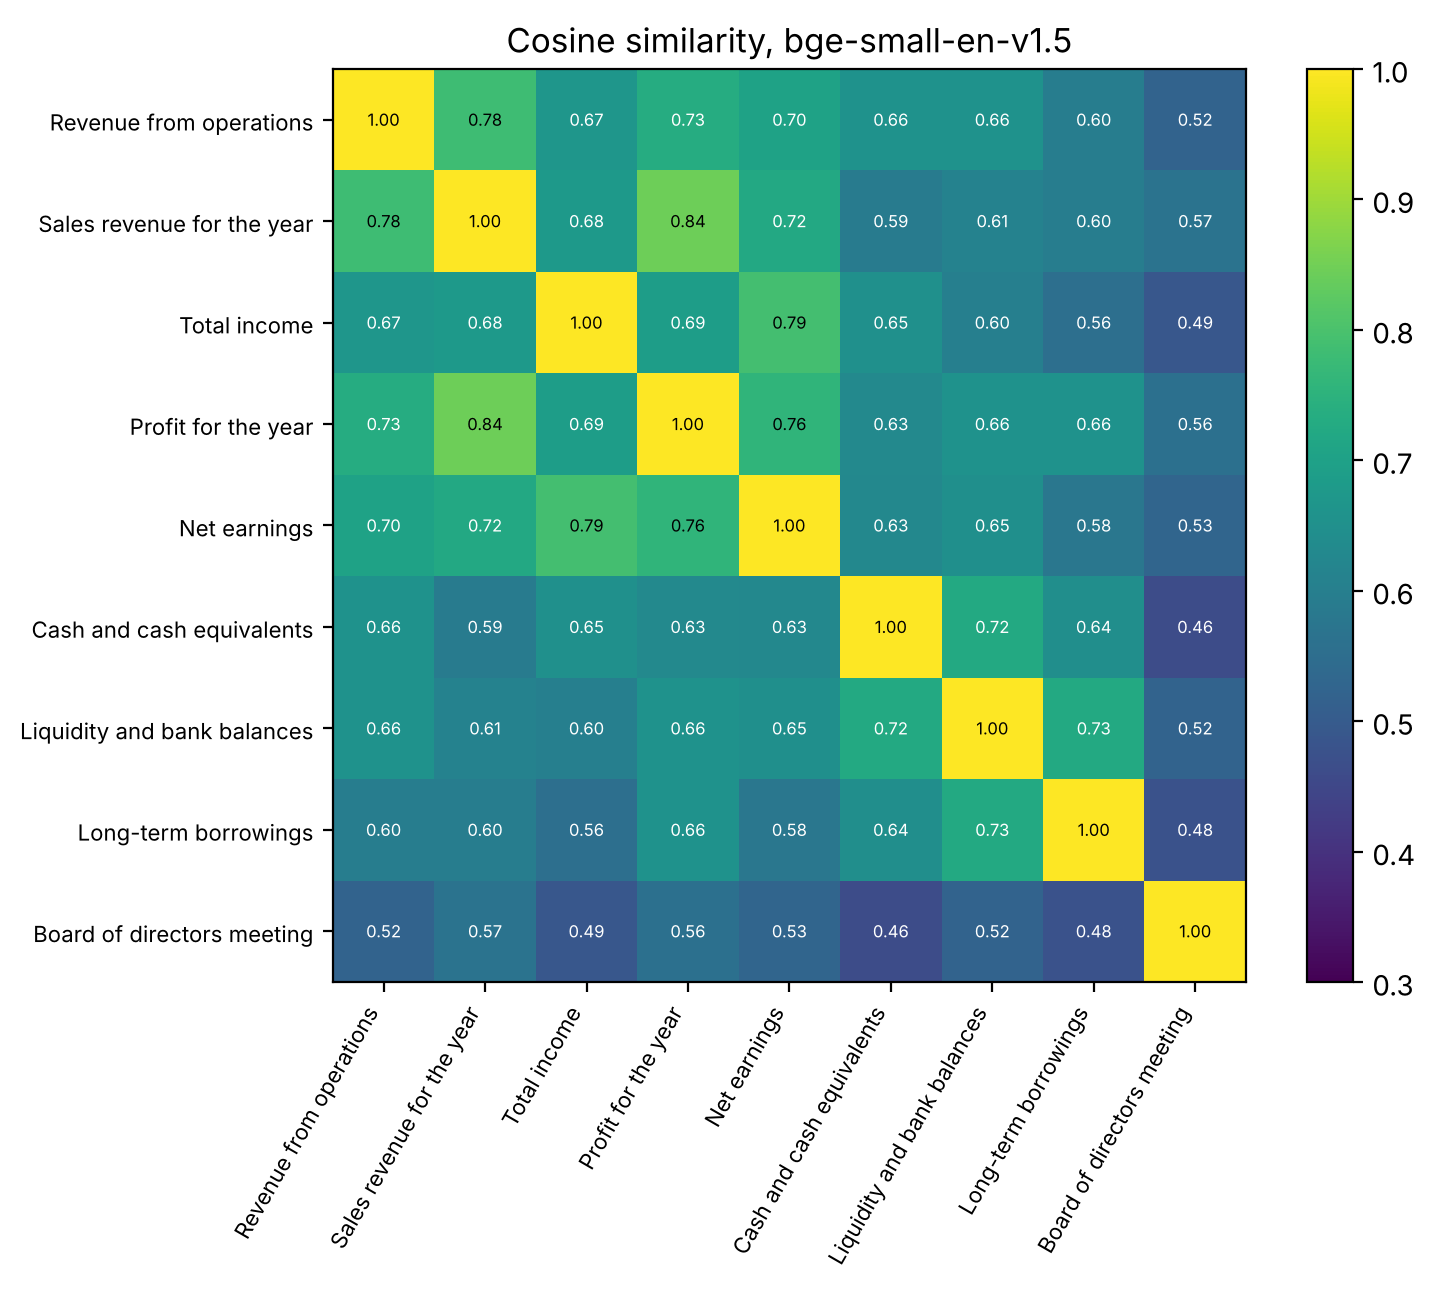

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(S, vmin=0.3, vmax=1.0, cmap="viridis")
ax.set_xticks(range(len(phrases)), phrases, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(phrases)), phrases, fontsize=8)
for i in range(len(phrases)):
    for j in range(len(phrases)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if S[i, j] < 0.75 else "black")
fig.colorbar(im); ax.set_title("Cosine similarity, bge-small-en-v1.5"); plt.tight_layout(); plt.show()

In [6]:
for i, p in enumerate(phrases):
    j = max((k for k in range(len(phrases)) if k != i), key=lambda k: S[i, k])
    print(f"{p:<30} most similar: {phrases[j]:<30} ({S[i, j]:.3f})")

Revenue from operations        most similar: Sales revenue for the year     (0.782)
Sales revenue for the year     most similar: Profit for the year            (0.844)
Total income                   most similar: Net earnings                   (0.790)
Profit for the year            most similar: Sales revenue for the year     (0.844)
Net earnings                   most similar: Total income                   (0.790)
Cash and cash equivalents      most similar: Liquidity and bank balances    (0.725)
Liquidity and bank balances    most similar: Long-term borrowings           (0.726)
Long-term borrowings           most similar: Liquidity and bank balances    (0.726)
Board of directors meeting     most similar: Sales revenue for the year     (0.568)


## 3. The BGE query instruction
BGE is trained so that *queries* are prefixed with an instruction and *passages* are not. FinRAG does this in `embed_query`.

In [7]:
query = "How much cash does the company hold?"
passages = ["Cash and Cash Equivalents | As at 31st March, 2025: 1,06,502", "Long-term borrowings increased during the year",
            "The Board met six times during the year"]
P = np.array(embeddings.embed_documents(passages))
q_instr = np.array(embeddings.embed_query(query))
q_plain = np.array(embeddings.embed_documents([query])[0])
for name, q in (("with instruction", q_instr), ("without instruction", q_plain)):
    print(name, [f"{s:.3f}" for s in P @ q])

with instruction ['0.628', '0.524', '0.441']
without instruction ['0.682', '0.580', '0.492']


## 4. Semantic search over real document chunks

In [8]:
from app.models import Document, DocumentChunk
db = nb.db_session()
user = nb.notebook_user(db)
doc = (db.query(Document).filter(Document.owner_id == user.id, Document.file_format == "pdf", Document.status == "processed")
       .order_by(Document.chunk_count.desc()).first())
chunks = db.query(DocumentChunk).filter_by(document_id=doc.id).order_by(DocumentChunk.chunk_index).all()
print(f"{doc.original_filename}: {len(chunks)} stored chunks")
import time
t = time.time()
C = np.array(embeddings.embed_documents([c.text for c in chunks]))
print(f"embedded {len(chunks)} chunks in {time.time() - t:.1f}s on {embeddings.device()}")

RIL-Integrated-Annual-Report-2023-24.pdf: 797 stored chunks


embedded 797 chunks in 59.7s on cpu


In [9]:
from app.document_processing.elements import describe_location
def search(question, k=3):
    scores = C @ np.array(embeddings.embed_query(question))
    for i in np.argsort(-scores)[:k]:
        print(f"  {scores[i]:.3f} | {describe_location(chunks[i].location):<28} | {nb.shorten(chunks[i].text, 110)}")

for q in ["What are the main risks the company faces?", "How much debt does the company have?", "Who are the auditors?"]:
    print("Q:", q); search(q)

Q: What are the main risks the company faces?
  0.700 | page 100 (printed p. 196)    | [Context: Liquidity risk arises from the Company’s inability to meet its cash flow commitments on the due dat…
  0.691 | page 40 (printed p. 77)      | [Context: The Company’s equity shares are (C in crore)] Exchange Act, 1934. Distillates Light 1,07,146 16,173…
  0.688 | page 18 (printed p. 32)      | Risk Description Risk Description Risk Description Sub-optimal customer experience The ability to attract, nu…
Q: How much debt does the company have?
  0.692 | page 98 (printed p. 192)     | [Context: to the Standalone Financial Statements for the year ended 31st March, 2024 | The Company adheres to…
  0.691 | page 103 (printed p. 202)    | [Context: to the Standalone Financial Statements for the year ended 31st March, 2024 | (C in crore) | (K in c…
  0.686 | page 98 (printed p. 192)     | [Context: to the Standalone Financial Statements for the year ended 31st March, 2024 | The Company adheres to…
Q:

## 5. Where embeddings fail: exact numbers and specific line items

In [10]:
pairs = [("Revenue from operations 9,80,136", "Revenue from operations 1,23,456"),
         ("Revenue from operations 9,80,136", "Other income 9,80,136"),
         ("Consolidated total assets", "Standalone total assets")]
for a, b in pairs:
    va, vb = np.array(embeddings.embed_documents([a, b]))
    print(f"{va @ vb:.3f}  {a!r} vs {b!r}")
db.close()

0.863  'Revenue from operations 9,80,136' vs 'Revenue from operations 1,23,456'
0.809  'Revenue from operations 9,80,136' vs 'Other income 9,80,136'
0.843  'Consolidated total assets' vs 'Standalone total assets'


## Interpretation
* The model clearly separates financial from non-financial text (the board-meeting phrase never exceeds 0.57), but it does **not**
  separate financial line items finely: in the saved run *Sales revenue for the year* was closest to *Profit for the year* (0.84),
  not to *Revenue from operations* (0.78).
* The query instruction lowered all three scores but did not change their order here. Absolute scores are only comparable within
  one mode; BGE recommends the instruction for retrieval, so FinRAG always uses it for questions.
* Dense search alone answered the debt question with standalone *notes* pages rather than the balance sheet.
* Changing the **number** changed the vector *less* (0.86) than keeping the number and changing the line item (0.81), and
  *consolidated* vs *standalone* scored 0.84. Embeddings find the *topic*; they cannot guarantee the exact figure or basis. That is
  why FinRAG combines dense search with PostgreSQL full-text search, adds extracted values as structured facts, and applies the basis
  guard (notebook 10).

## Common errors and troubleshooting
| Symptom | Cause | Fix |
|---|---|---|
| Download error on first use | No access to huggingface.co | Allow the host or pre-download the model into `HF_HOME` |
| Very slow embedding | CPU, long texts | Batch (FinRAG uses 32), shorter chunks, or a GPU |
| Poor retrieval for questions | Query embedded without the instruction | Use `embed_query` for questions, `embed_documents` for passages |
| Dimension mismatch in Qdrant | Changed the model but kept the collection | Re-create the collection and reprocess documents |

## Practical exercises
1. Add five phrases from your own reports to the heatmap. Which ones does the model confuse?
2. Measure how much the similarity changes when you change only the year (2024-25 → 2023-24).
3. Compare top-3 results with and without the query instruction for ten questions about your document.

## Summary
You tokenised text, produced real BGE embeddings, measured cosine similarity, searched real chunks semantically, and demonstrated the
limits that motivate FinRAG's hybrid retrieval.

## Further learning
* BGE model card: https://huggingface.co/BAAI/bge-small-en-v1.5
* Sentence-Transformers: https://www.sbert.net/
* Next: **09 — Qdrant vector search**.